# Job Market Analysis and Recommendation System

## Project Overview

* This project analyzes job market data to understand salary patterns, emerging job categories, high-demand roles, country-wise hourly rates and remote-work trends. 
    
* It also uses machine learning for job demand forecasting and develops a job recommendation system with a Flask API and interactive dashboard.

* **Tools & Technologies:** Python, Pandas, NumPy, Plotly, Scikit-learn, Flask, SQL, and Docker.


# Import Libraries

In [2]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")


Libraries imported successfully!


# Load Dataset

In [3]:
data_path = Path("Job Market Analysis.csv")
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# Dataset Overview

### Check Dataset Shape

In [4]:
rows, columns = df.shape

print("Number of Rows   :", rows)
print("Number of Columns:", columns)

Number of Rows   : 244828
Number of Columns: 8


# Check Column Names

In [5]:
print("Columns in the Dataset:\n")

for column in df.columns:
    print(column)

Columns in the Dataset:

title
link
published_date
is_hourly
hourly_low
hourly_high
budget
country


# Check Data Types

In [6]:
data_types = pd.DataFrame({"Column Name": df.columns, "Data Type": df.dtypes.astype(str).values})

display(data_types)

,Column Name,Data Type
0,title,object
1,link,object
2,published_date,object
3,is_hourly,bool
4,hourly_low,float64
5,hourly_high,float64
6,budget,float64
7,country,object


* The dataset contains different types of attributes, including job details, compensation information, publication dates and country.

* Numerical columns can be used for salary and budget analysis while categorical columns can help identify job-market patterns.

### Basic Statistical Summary

In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
hourly_low,102422.0,17.339644,18.140065,3.0,8.0,15.0,20.0,998.0
hourly_high,98775.0,41.970610,47.850892,3.0,20.0,30.0,50.0,999.0
budget,103891.0,911.473564,15729.738834,5.0,25.0,100.0,300.0,1000000.0


* Hourly Low and Hourly High : Mean and median values help us understand the typical hourly payment range for jobs.

* Project Budget : A large difference between the mean and median may indicate that a small number of projects have very high budgets.

* Data Distribution : Minimum, maximum and quartile values help identify the spread of compensation values and potential outliers.

# Missing Value Analysis

In [8]:
missing_summary = pd.DataFrame({"Missing Values": df.isnull().sum(), "Missing Percentage (%)": (df.isnull().sum() / len(df)) * 100})

missing_summary = missing_summary.sort_values(by = "Missing Percentage (%)", ascending = False)

display(missing_summary.round(2))

,Missing Values,Missing Percentage (%)
hourly_high,146053,59.66
hourly_low,142406,58.17
budget,140937,57.57
country,5077,2.07
title,1,0.00
link,1,0.00
published_date,0,0.00
is_hourly,0,0.00


* The hourly_high column has the highest number of missing values with **1,46,053** records (59.66%).

* The hourly_low column contains **1,42,406** missing values (58.17%), while budget has **1,40,937** missing values (57.57%).

* The country column has **5,077** missing values (2.07%). These were handled by assigning "Unknown" during preprocessing.

# Handle Missing Title, Link & Country

In [9]:
rows_before = len(df)

# Remove records with missing title or link
df.dropna(subset=["title", "link"], inplace=True)
df.reset_index(drop=True, inplace=True)

# Replace missing country values
df["country"] = df["country"].fillna("Unknown")

print("Rows Before Cleaning:", rows_before)
print("Rows After Cleaning :", len(df))

print("\nMissing Values After Cleaning:")
display(df[["title", "link", "country"]].isnull().sum())

print("\nUnknown Country Records:", (df["country"] == "Unknown").sum())

Rows Before Cleaning: 244828
Rows After Cleaning : 244827

Missing Values After Cleaning:


title      0
link       0
country    0
dtype: int64


Unknown Country Records: 5076


# Job Type and Compensation Analysis

In [10]:
compensation_summary = df.groupby("is_hourly").agg(Total_Jobs = ("is_hourly", "size"), Hourly_Low_Available = ("hourly_low", "count"),
                                                   Hourly_High_Available = ("hourly_high", "count"), Budget_Available = ("budget", "count"))

compensation_summary.index = compensation_summary.index.map({True: "Hourly Jobs", False: "Fixed-Budget Jobs"})

display(compensation_summary)

,Total_Jobs,Hourly_Low_Available,Hourly_High_Available,Budget_Available
is_hourly,,,,
Fixed-Budget Jobs,103891,0,0,103891
Hourly Jobs,140936,102422,98775,0


* The dataset contains **1,40,936** hourly jobs and **1,03,891** fixed-budget jobs after data cleaning.

* Among hourly jobs the minimum hourly rate is available for **1,02,422** records, while the maximum hourly rate is available for **98,775** records.

* The budget is available for **1,03,891** fixed-budget jobs.

# Duplicate Record Analysis

In [11]:
duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Total Duplicate Records:", duplicate_count)
print("Duplicate Percentage   :", round(duplicate_percentage, 2), "%")

Total Duplicate Records: 0
Duplicate Percentage   : 0.0 %


* The dataset contains **0** duplicate records, with a duplicate percentage of 0.0%.

# Date Time Data Type Verification

In [12]:
print("Published Date Data Type:", df["published_date"].dtype)

print("\nEarliest Job Publication Date:")
print(df["published_date"].min())

print("\nLatest Job Publication Date:")
print(df["published_date"].max())

Published Date Data Type: object

Earliest Job Publication Date:
2023-11-02 09:22:02+00:00

Latest Job Publication Date:
2024-03-24 14:16:47+00:00


# Date Time Conversion

In [13]:
df["published_date"] = pd.to_datetime(df["published_date"], errors = "coerce", utc = True)

print("Updated Data Type:", df["published_date"].dtype)
print("Invalid Dates:", df["published_date"].isna().sum())

Updated Data Type: datetime64[ns, UTC]
Invalid Dates: 0


# Date Feature Extraction

In [14]:
df["published_year"] = df["published_date"].dt.year
df["published_month"] = df["published_date"].dt.month
df["published_month_name"] = df["published_date"].dt.strftime("%B")
df["published_day"] = df["published_date"].dt.day
df["published_weekday"] = df["published_date"].dt.day_name()

display(df[["published_date", "published_year", "published_month", "published_month_name", "published_day", "published_weekday"]].head())

,published_date,published_year,published_month,published_month_name,published_day,published_weekday
0,2024-02-17 09:09:54+00:00,2024,2,February,17,Saturday
1,2024-02-17 09:09:17+00:00,2024,2,February,17,Saturday
2,2024-02-17 09:08:46+00:00,2024,2,February,17,Saturday
3,2024-02-17 09:08:08+00:00,2024,2,February,17,Saturday
4,2024-02-17 09:07:42+00:00,2024,2,February,17,Saturday


* The date features have been extracted successfully from published_date.

* The displayed records belong to **February 2024** and their weekday is Saturday.

* The extracted month and year columns will help analyze job-posting trends over time.

# Final Dataset Quality Check

In [15]:
print("Final Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

Final Dataset Shape: (244827, 13)
Total Missing Values: 429393
Duplicate Records: 0


In [16]:
# Verify Current Dataset
print("Dataset Shape:", df.shape)

print("\nMissing Values in Key Columns:")
display(df[["title", "link", "country", "published_date"]].isnull().sum())

print("\nUnknown Country Records:", (df["country"] == "Unknown").sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (244827, 13)

Missing Values in Key Columns:


title             0
link              0
country           0
published_date    0
dtype: int64


Unknown Country Records: 5076

Duplicate Records: 0


* After preprocessing the dataset contains **2,44,827** job records and **13** columns.

* Missing values in the title, link and country columns have been handled successfully.

* A total of **5,076** records have an unknown country, and these records have been retained.

* No duplicate records were found in the cleaned dataset.

# Exploratory Data Analysis

### Job Type Distribution

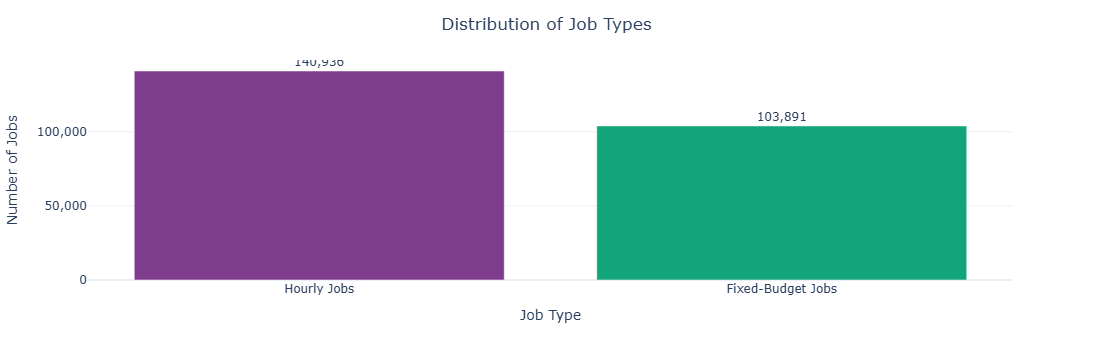

In [17]:
job_type_summary = (df["is_hourly"].map({True: "Hourly Jobs", False: "Fixed-Budget Jobs"}).value_counts().rename_axis("Job Type").reset_index(name="Job Count"))

job_type_summary["Percentage"] = (job_type_summary["Job Count"] / len(df) * 100)

fig = px.bar(job_type_summary, x = "Job Type", y = "Job Count", color = "Job Type", color_discrete_sequence = px.colors.qualitative.Bold,
             text = "Job Count", hover_data = {"Percentage": ":.2f"})

fig.update_traces(texttemplate="%{text:,}", textposition="outside")

fig.update_layout(title = "Distribution of Job Types", title_x = 0.5, template = "plotly_white", xaxis_title = "Job Type",
                  yaxis_title = "Number of Jobs", yaxis_tickformat = ",", showlegend = False)

fig.show()

* The dataset contains **2,44,827** job postings after preprocessing.

* Hourly jobs account for approximately 57.57% **1,40,936** postings of all job postings.

* Fixed-budget jobs account for approximately 42.43% **1,03,891** postings.

### Top 10 Job Titles 

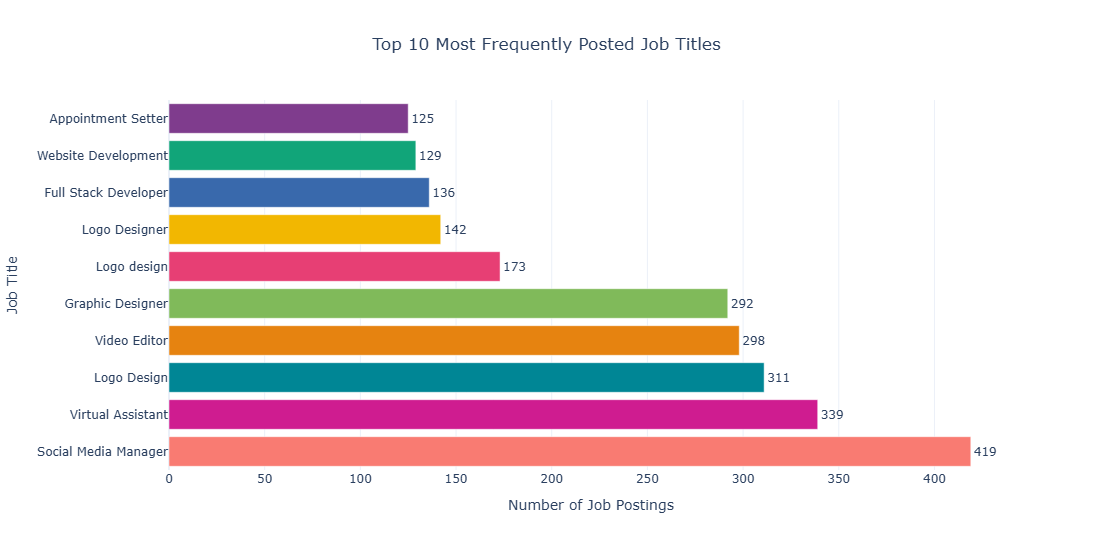

In [18]:
top_titles = (df["title"].value_counts().head(10).sort_values(ascending = True).reset_index())

top_titles.columns = ["Job Title", "Job Count"]

fig = px.bar(top_titles, x = "Job Count", y = "Job Title", orientation = "h", color = "Job Title", color_discrete_sequence = px.colors.qualitative.Bold,
             text = "Job Count", hover_data = {"Job Count": True}, title = "Top 10 Most Frequently Posted Job Titles")

fig.update_traces(texttemplate = "%{text:,}", textposition = "outside", cliponaxis = False)

fig.update_layout(title_x = 0.5, template = "plotly_white", xaxis_title = "Number of Job Postings", yaxis_title = "Job Title",
                  xaxis_tickformat = ",", showlegend = False, height = 550)

fig.show()

* Social Media Manager is the most frequently posted job title among the top 10 with **419** postings.

* Virtual Assistant ranks second, with **339** postings.

* Video Editor has **298** postings while Graphic Designer has **292** postings.

### Country Wise Job Posting

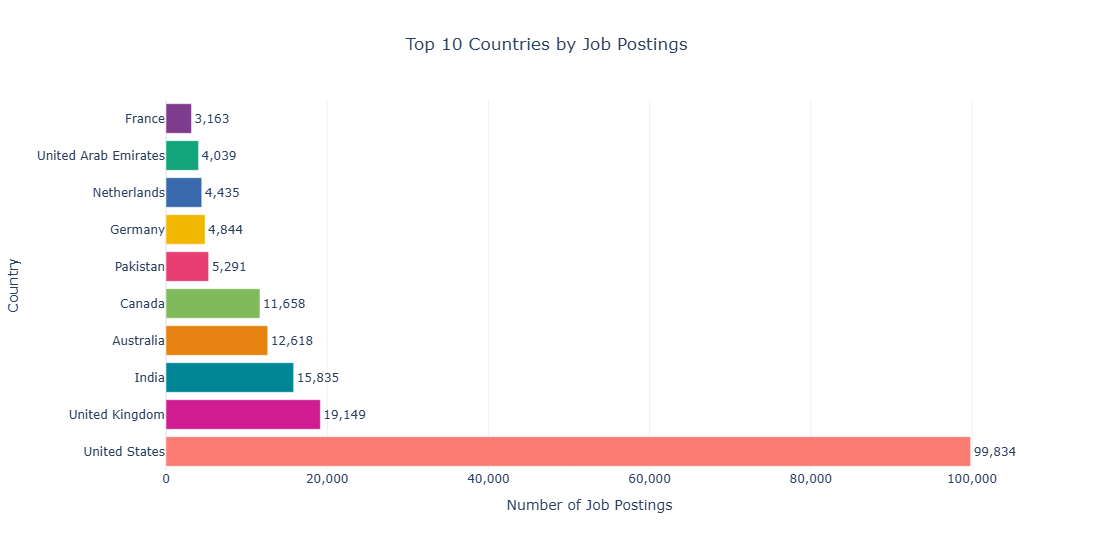

In [19]:
country_summary = (df.loc[df["country"] != "Unknown", "country"].value_counts().head(10).sort_values(ascending = True).reset_index())

country_summary.columns = ["Country", "Job Count"]

fig = px.bar(country_summary, x = "Job Count", y = "Country", orientation = "h", color = "Country", color_discrete_sequence = px.colors.qualitative.Bold,
             text = "Job Count", title = "Top 10 Countries by Job Postings", hover_data = {"Job Count": True})

fig.update_traces(texttemplate = "%{text:,}", textposition = "outside", cliponaxis = False)

fig.update_layout(title_x = 0.5, template = "plotly_white", xaxis_title = "Number of Job Postings", yaxis_title = "Country",
                  xaxis_tickformat = ",", showlegend = False, height = 550)

fig.show()

* The United States has the highest number of job postings in the dataset with **99,834** postings.

* The United Kingdom ranks second, with **19,149** postings.

* India has **15,835** postings, followed by Australia with **12,618** and Canada with **11,658**.

### Hourly Rate Analysis

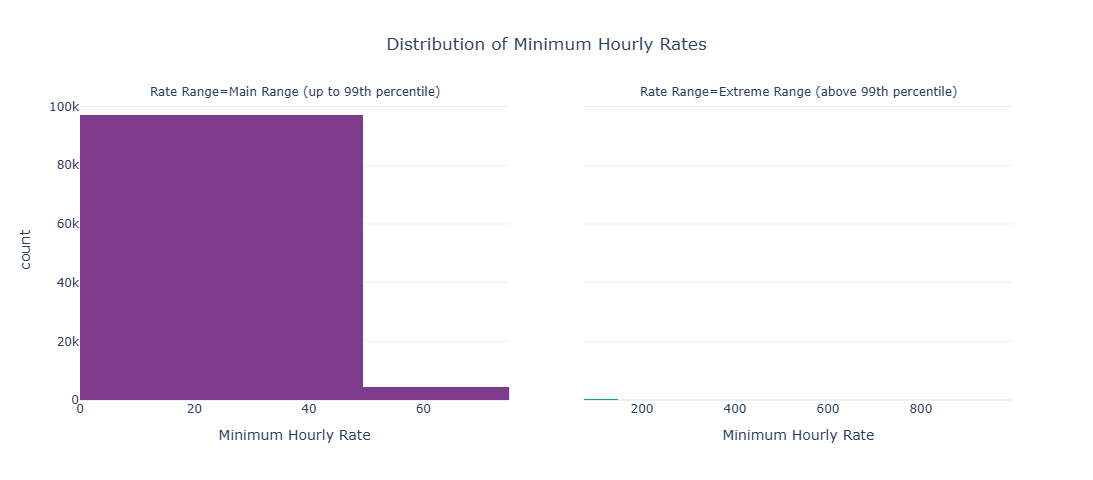

In [20]:
hourly_low_data = df["hourly_low"].dropna()

p99 = hourly_low_data.quantile(0.99)

fig = px.histogram(pd.DataFrame({"Hourly Rate": hourly_low_data, "Rate Range": np.where(hourly_low_data <= p99, "Main Range (up to 99th percentile)",
                                                                                        "Extreme Range (above 99th percentile)")}), x = "Hourly Rate",
                   color = "Rate Range", facet_col = "Rate Range", facet_col_spacing = 0.08, nbins = 35, color_discrete_sequence = px.colors.qualitative.Bold,
                   title = "Distribution of Minimum Hourly Rates", labels = {"Hourly Rate": "Minimum Hourly Rate", "count": "Number of Jobs"})

fig.update_layout(template = "plotly_white", title_x = 0.5, showlegend = False, height = 480)

fig.update_xaxes(matches=None)
fig.update_xaxes(range=[0, p99], col=1)
fig.update_xaxes(range=[p99, hourly_low_data.max()], col=2)

fig.show()

* The histogram shows the distribution of minimum hourly rates in the dataset.

* Most rates can be examined in the main distribution panel, while values above the 99th percentile are displayed separately.

### Average Hourly Rate Comparison

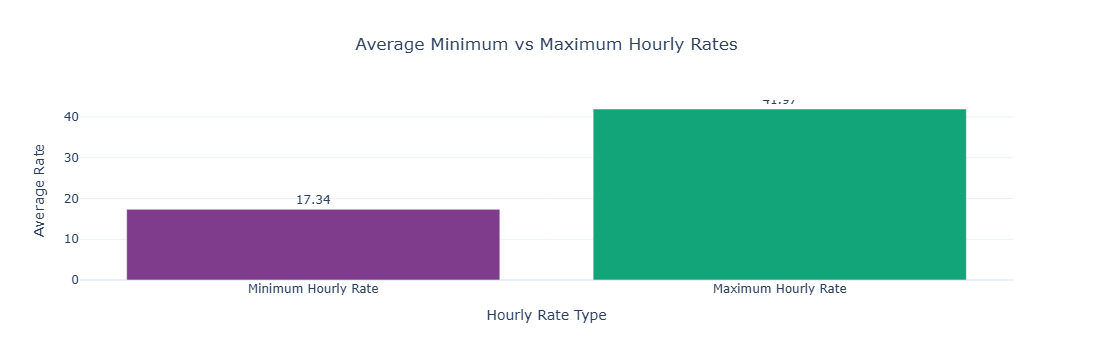

In [21]:
hourly_summary = pd.DataFrame({"Hourly Rate": ["Minimum Hourly Rate", "Maximum Hourly Rate"], "Average Rate": [df["hourly_low"].mean(),
                                                                                                               df["hourly_high"].mean()]})

fig = px.bar(hourly_summary, x = "Hourly Rate", y = "Average Rate", color = "Hourly Rate", text = "Average Rate", color_discrete_sequence = px.colors.qualitative.Bold,
             title = "Average Minimum vs Maximum Hourly Rates", hover_data = {"Average Rate": ":.2f"})

fig.update_traces(texttemplate = "%{text:.2f}", textposition = "outside")

fig.update_layout(title_x = 0.5, template = "plotly_white", xaxis_title = "Hourly Rate Type", yaxis_title = "Average Rate", showlegend = False)

fig.show()

* The average minimum hourly rate is **17.34** calculated from **1,02,422** available records.

* The average maximum hourly rate is **41.97** calculated from **98,775** available records.

* The average maximum rate is approximately **24.63** higher than the average minimum rate.

* The median minimum hourly rate is **15.00** while the median maximum hourly rate is **30.00**.

## Bivariate Analysis

### Job Type vs Country

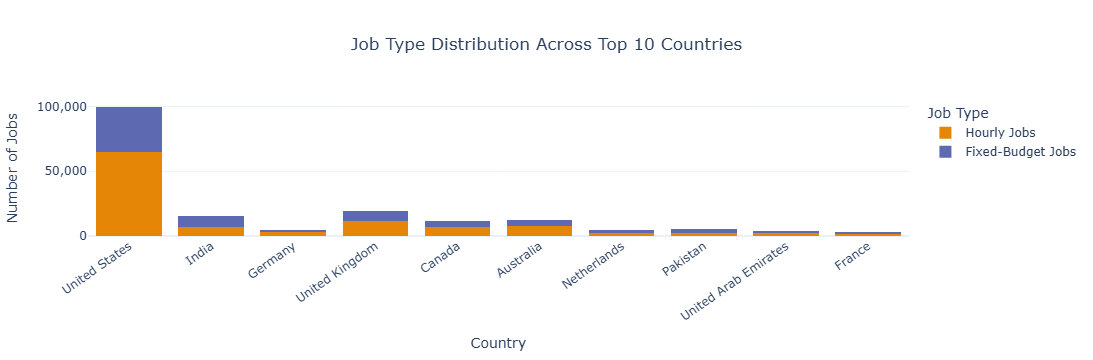

In [22]:
top_countries = (df[df["country"] != "Unknown"]["country"].value_counts().head(10).index)

country_job_type = df[df["country"].isin(top_countries)].copy()

country_job_type["Job Type"] = country_job_type["is_hourly"].map({True: "Hourly Jobs", False: "Fixed-Budget Jobs"})

fig = px.histogram(country_job_type, x = "country", color = "Job Type", barmode = "stack", color_discrete_sequence = px.colors.qualitative.Vivid,
                   title = "Job Type Distribution Across Top 10 Countries", labels = {"country": "Country", "count": "Number of Jobs"},
                   category_orders={"Job Type": ["Hourly Jobs", "Fixed-Budget Jobs"]})

fig.update_layout(title_x = 0.5, template = "plotly_white", xaxis_title = "Country", yaxis_title = "Number of Jobs", yaxis_tickformat = ",",
                  legend_title = "Job Type", xaxis_tickangle = -35)

fig.update_traces(hovertemplate=("Country: %{x}<br>""Number of Jobs: %{y:,}""<extra></extra>"))

fig.show()

* The United States has the highest number of job postings with **99,834** postings including **64,794** hourly jobs and **35,040** fixed-budget jobs.

* The United Kingdom has **19,149** postings consisting of **11,335** hourly jobs and **7,814** fixed-budget jobs.

* India shows a different pattern : **9,046** fixed-budget jobs compared with **6,789** hourly jobs.

* Australia has **7,679** hourly jobs and **4,939** fixed-budget jobs while Canada has **7,086** hourly jobs and **4,572** fixed-budget jobs.

### Hourly Rate Distribution By Job Type

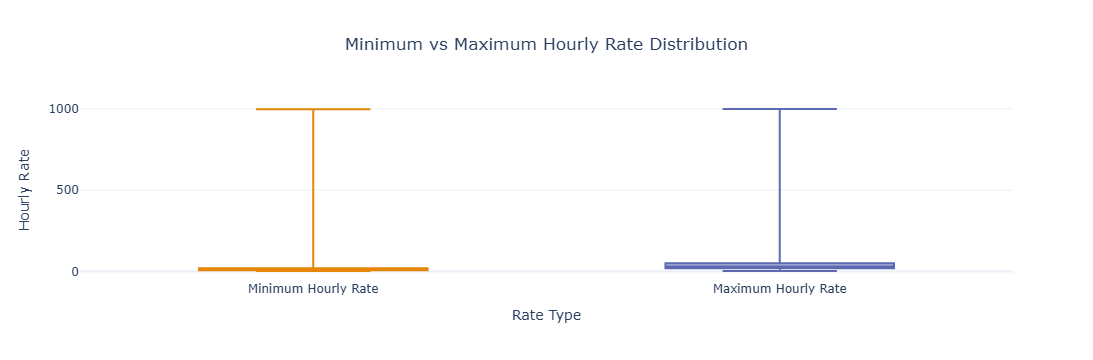

In [23]:
hourly_rates = df[df["is_hourly"] == True].copy()

hourly_rates = hourly_rates.melt(id_vars = ["title"], value_vars = ["hourly_low", "hourly_high"], var_name = "Rate Type", value_name = "Hourly Rate")

hourly_rates["Rate Type"] = hourly_rates["Rate Type"].map({"hourly_low": "Minimum Hourly Rate", "hourly_high": "Maximum Hourly Rate"})

fig = px.box(hourly_rates.dropna(subset=["Hourly Rate"]), x = "Rate Type", y = "Hourly Rate", color = "Rate Type", color_discrete_sequence = px.colors.qualitative.Vivid,
             title = "Minimum vs Maximum Hourly Rate Distribution", points = False, hover_data = ["title"])

fig.update_layout(title_x = 0.5, template = "plotly_white", xaxis_title = "Rate Type", yaxis_title = "Hourly Rate", showlegend = False)

fig.show()

* The median minimum hourly rate is **15.00** while the median maximum hourly rate is **30.00**.

* The middle 50% of minimum hourly rates lies between **8.00** and **20.00**.

* The middle 50% of maximum hourly rates lies between **20.00** and **50.00**.

### Country vs Average Hourly Rate

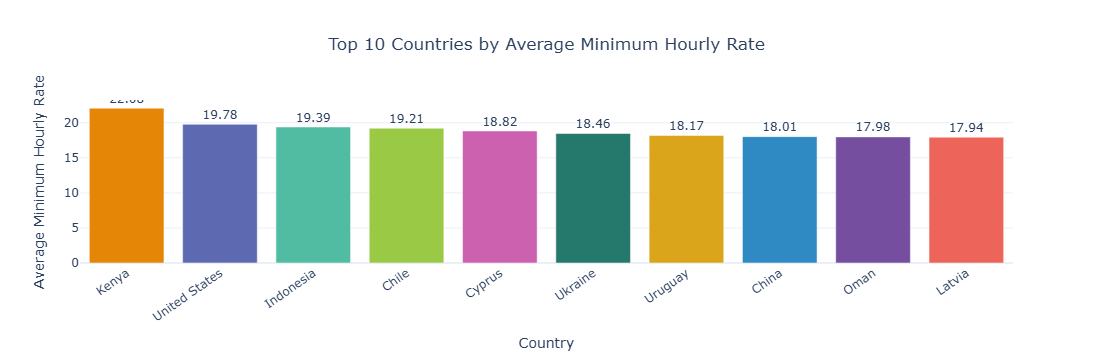

In [24]:
country_rates = (df[df["country"] != "Unknown"].dropna(subset = ["hourly_low"]).groupby("country").agg(Average_Hourly_Rate = ("hourly_low", "mean"),
                                                                                                       Job_Count=("hourly_low", "count")).query("Job_Count >= 30")
    .sort_values("Average_Hourly_Rate", ascending=False).head(10).reset_index())

fig = px.bar(country_rates, x = "country", y = "Average_Hourly_Rate", color = "country", text = "Average_Hourly_Rate", color_discrete_sequence = px.colors.qualitative.Vivid,
             title = "Top 10 Countries by Average Minimum Hourly Rate", hover_data = {"Job_Count": True, "Average_Hourly_Rate": ":.2f"})

fig.update_traces(texttemplate = "%{text:.2f}", textposition = "outside", hovertemplate = ("Country: %{x}<br>""Average Minimum Rate: %{y:.2f}<br>""<extra></extra>"))

fig.update_layout(title_x = 0.5, template = "plotly_white", xaxis_title = "Country", yaxis_title = "Average Minimum Hourly Rate", showlegend = False,
                  xaxis_tickangle = -35)

fig.show()

* Kenya has the highest average minimum hourly rate among the ten countries shown at **22.08** based on **369** records.

* The United States ranks second with an average minimum hourly rate of **19.78** across **48,195** records.

* Indonesia ranks third at **19.39** based on **234** records.

* Latvia ranks tenth among the displayed countries with an average minimum hourly rate of **17.94** across **111** records.

## Multivariate Analysis

### Country, Job Type & Job Count

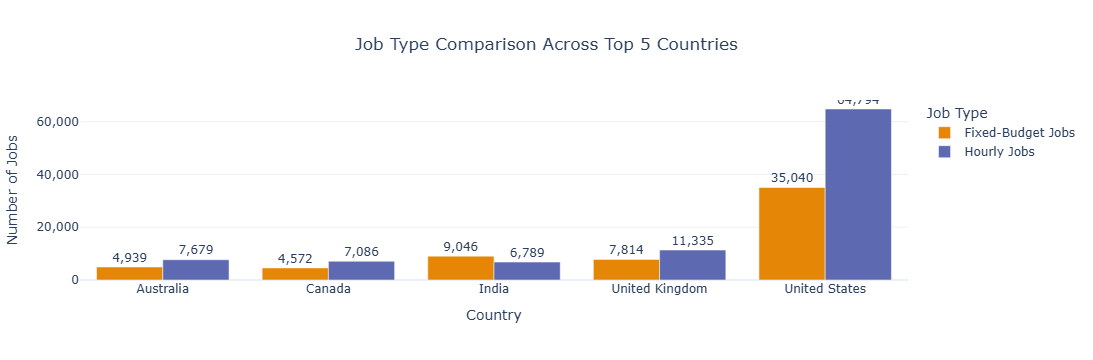

In [25]:
top_5_countries = (df[df["country"] != "Unknown"]["country"].value_counts().head(5).index)

multi_df = df[df["country"].isin(top_5_countries)].copy()

multi_df["Job Type"] = multi_df["is_hourly"].map({True: "Hourly Jobs", False: "Fixed-Budget Jobs"})

multi_summary = (multi_df.groupby(["country", "Job Type"]).size().reset_index(name="Job Count"))

multi_summary["Percentage"] = (multi_summary["Job Count"]/ multi_summary.groupby("country")["Job Count"].transform("sum")* 100)

fig = px.bar(multi_summary, x = "country", y = "Job Count", color = "Job Type", barmode = "group", text = "Job Count",
             color_discrete_sequence = px.colors.qualitative.Vivid, title = "Job Type Comparison Across Top 5 Countries",
             hover_data = {"Percentage": ":.2f", "Job Count": True})

fig.update_traces(texttemplate = "%{text:,}", textposition = "outside")

fig.update_layout(title_x = 0.5, template = "plotly_white", xaxis_title = "Country", yaxis_title = "Number of Jobs", yaxis_tickformat = ",", legend_title="Job Type")

fig.show()

* The United States has the highest number of postings among the five countries with **64,794** hourly jobs and **35,040** fixed-budget jobs.

* In the United States hourly jobs account for 64.90% of postings while fixed-budget jobs account for 35.10%.

* The United Kingdom has **11,335** hourly jobs and **7,814** fixed-budget jobs. 
    
* Hourly jobs represent 59.19% of its postings.

* India shows the opposite pattern : **9,046** fixed-budget jobs 57.13% compared with **6,789** hourly jobs 42.87%.

### Job Titles vs Hourly Rate

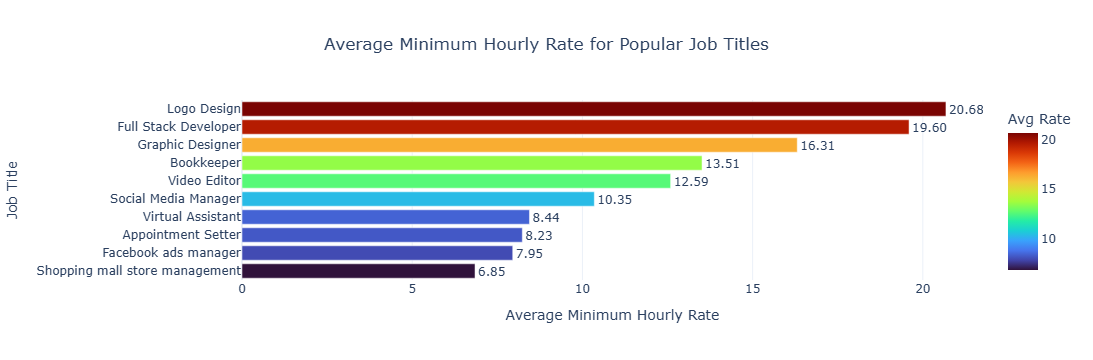

In [26]:
top_hourly_titles = (df.dropna(subset = ["title", "hourly_low"]).groupby("title").agg(Average_Min_Rate = ("hourly_low", "mean"),
                                                                                      Job_Count = ("hourly_low", "count")).query("Job_Count >= 10")
    .sort_values("Job_Count", ascending = False).head(10).sort_values("Average_Min_Rate", ascending = True).reset_index())

fig = px.bar(top_hourly_titles, x = "Average_Min_Rate", y = "title", orientation = "h", color = "Average_Min_Rate", color_continuous_scale = "Turbo",
             text = "Average_Min_Rate", title = "Average Minimum Hourly Rate for Popular Job Titles", hover_data = {"Job_Count": True, "Average_Min_Rate": ":.2f"})

fig.update_traces(texttemplate = "%{text:.2f}", textposition = "outside")

fig.update_layout(title_x = 0.5, template = "plotly_white", xaxis_title = "Average Minimum Hourly Rate", yaxis_title = "Job Title", coloraxis_colorbar_title = "Avg Rate")

fig.show()

* Logo Design has the highest average minimum hourly rate among the ten displayed titles at **20.68** based on **81** records.

* Full Stack Developer ranks second with an avearage minimum rate of **19.60** across **84** records.

* Graphic Designer has an average minimum rate of **16.31** based on **164** records.

* Social Media Manager has **260** records the highest count among these ten titles with an average minimum rate of **10.35**.

### Time Based Analysis Monthly Job Trends

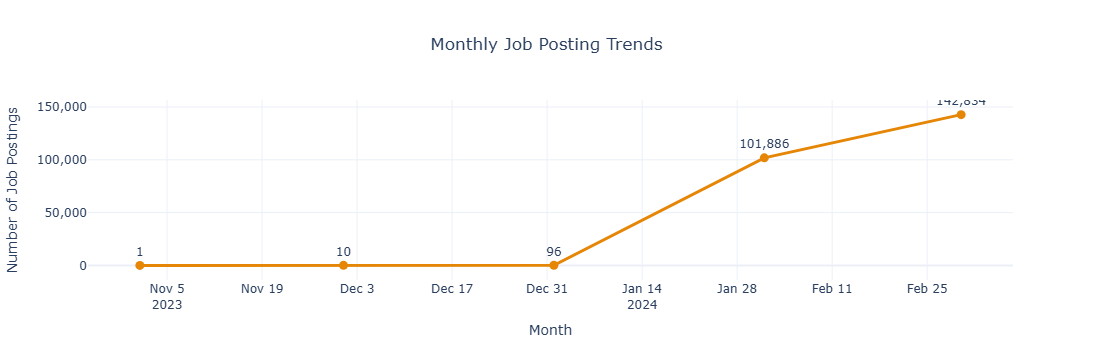

In [27]:
monthly_jobs = (df.dropna(subset=["published_date"]).assign(Month = lambda x: (x["published_date"].dt.tz_localize(None).dt.to_period("M").astype(str)))
    .groupby("Month").size().reset_index(name = "Job Count"))

fig = px.line(monthly_jobs, x = "Month", y = "Job Count", markers = True, text = "Job Count", color_discrete_sequence = px.colors.qualitative.Vivid,
              title = "Monthly Job Posting Trends", labels = {"Month": "Month","Job Count": "Number of Job Postings"})

fig.update_traces(texttemplate = "%{text:,}", textposition = "top center", line = dict(width = 3), marker = dict(size = 9),
                  hovertemplate="Month: %{x}<br>Job Postings: %{y:,}<extra></extra>")

fig.update_layout(title_x = 0.5, template = "plotly_white", yaxis_tickformat = ",")

fig.show()

* The dataset contains 1 posting in **November 2023** 10 in **December 2023** and 96 in **January 2024**.

* The recorded count rises sharply to **1,01,886** in February 2024 and **1,42,834** in March 2024.

* March has **40,948** more postings than February an increase of approximately 40.19%.

# Correlation Heatmap

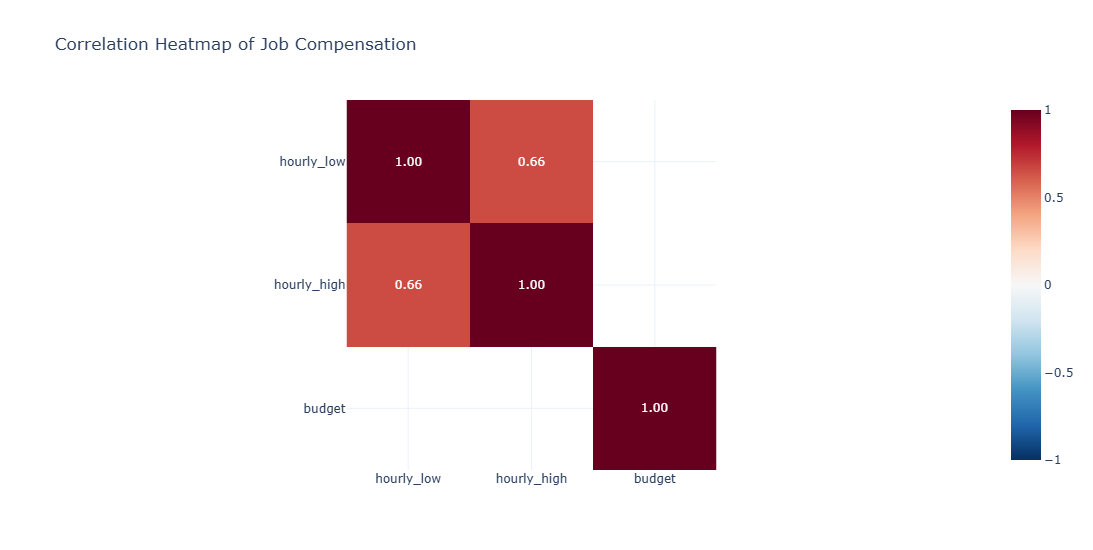

In [28]:
numeric_cols = ['hourly_low', 'hourly_high', 'budget']

# Calculate correlation
corr_matrix = df[numeric_cols].corr()

# Create heatmap
fig = px.imshow(corr_matrix, text_auto = '.2f', color_continuous_scale = 'RdBu_r', zmin = -1, zmax = 1,
    title='Correlation Heatmap of Job Compensation')

fig.update_layout(template = 'plotly_white', width = 750, height = 550)

fig.show()

* The heatmap is designed to examine the relationship between minimum hourly rates maximum hourly rates and fixed-job budgets.

* A correlation value closer to **+1** indicates a strong positive linear relationship while a value closer to **-1** indicates a strong negative linear relationship.

# Outlier Detection

In [30]:
compensation_cols = ['hourly_low', 'hourly_high', 'budget']

outlier_results = []

for col in compensation_cols:
    values = df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[(values < lower_bound) | (values > upper_bound)]

    outlier_results.append({'Column': col, 'Valid Values': len(values), 'Lower Bound': round(lower_bound, 2), 'Upper Bound': round(upper_bound, 2),
                            'Outlier Count': len(outliers),'Outlier Percentage (%)': round(len(outliers) / len(values) * 100, 2) if len(values) else 0})

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Column,Valid Values,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,hourly_low,102422,-10.0,38.0,8450,8.25
1,hourly_high,98775,-25.0,95.0,7029,7.12
2,budget,103891,-387.5,712.5,12993,12.51


* Hourly Minimum Rate : Outliers account for 8.25% of valid values with **8,450** observations outside the IQR limits.

* Hourly Maximum Rate : Outliers account for 7.12% of valid values with **7,029** observations outside the IQR limits.

* Fixed Job Budget : The budget column has the highest outlier percentage at 12.51% representing **12,993** observations.

# Distribution Of Minimum & Maximum Hourly Rates

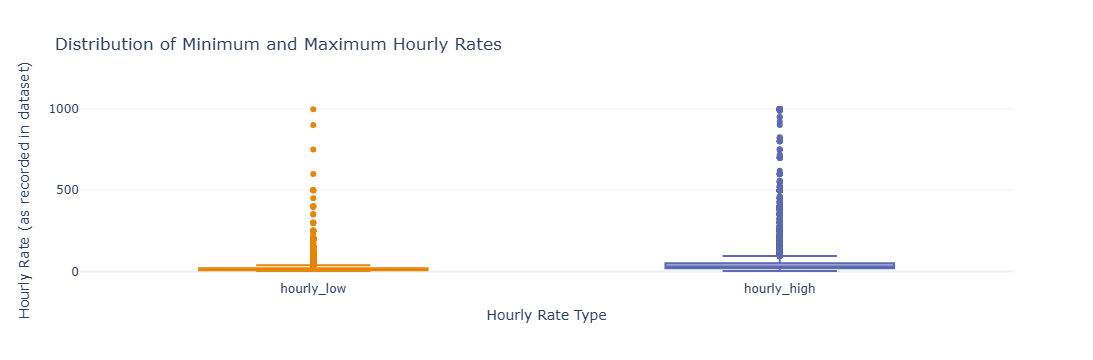

In [31]:
hourly_compensation = df[['hourly_low', 'hourly_high']].melt(var_name = 'Compensation Type', value_name = 'Amount').dropna()

fig = px.box(hourly_compensation, x = 'Compensation Type', y = 'Amount', color = 'Compensation Type', points = 'outliers',
             color_discrete_sequence = px.colors.qualitative.Vivid, title = 'Distribution of Minimum and Maximum Hourly Rates')

fig.update_layout(template = 'plotly_white', showlegend = False, xaxis_title = 'Hourly Rate Type', yaxis_title = 'Hourly Rate (as recorded in dataset)')

fig.show()

* The median minimum hourly rate is **15.00** compared with **30.00** for the maximum hourly rate.

* The middle 50% of minimum rates falls between **8.00** and **20.00**.

* The middle 50% of maximum rates falls between **20.00** and **50.00**.



# Job Title Keywords and Salary Analysis

,Keyword,Job Count,Salary Correlation
314,independent,109,0.220
54,attorney,188,0.103
350,lawyer,217,0.082
624,tax,656,0.070
141,consultant,913,0.069
142,consultation,341,0.058
358,life,138,0.058
249,financial,567,0.056
320,insurance,168,0.056
355,legal,426,0.055


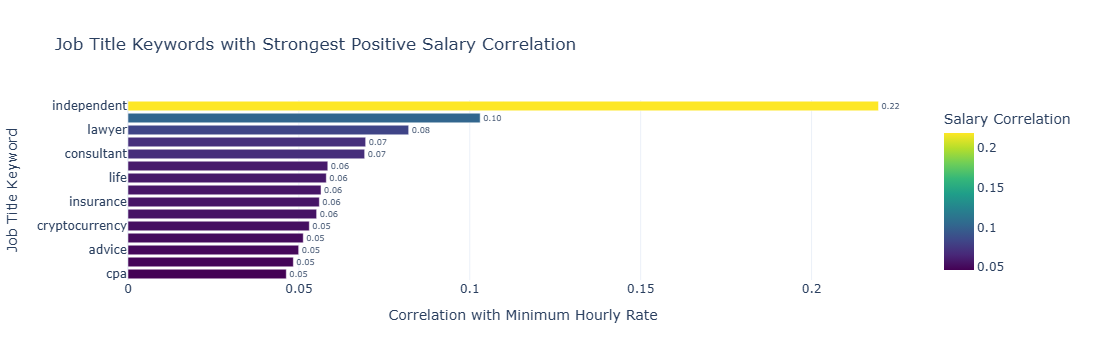

In [32]:
from sklearn.feature_extraction.text import CountVectorizer

# Select hourly jobs with available minimum hourly rates
salary_df = df.loc[df['is_hourly'] & df['hourly_low'].notna(),['title', 'hourly_low']].copy()

salary_df['title'] = salary_df['title'].fillna('').str.lower()

# Convert job titles into keyword features
vectorizer = CountVectorizer(stop_words = 'english', token_pattern = r'(?u)\b[a-zA-Z]{3,}\b', min_df = 100, binary = True)

X = vectorizer.fit_transform(salary_df['title'])
keywords = vectorizer.get_feature_names_out()

# Calculate correlation between each keyword and minimum hourly rate
salary_values = salary_df['hourly_low'].reset_index(drop=True)
keyword_results = []

for i, keyword in enumerate(keywords):
    keyword_present = X[:, i].toarray().ravel()
    job_count = int(keyword_present.sum())

    if 1 < job_count < len(keyword_present):
        correlation = pd.Series(keyword_present).corr(salary_values)

        if pd.notna(correlation):
            keyword_results.append({'Keyword': keyword,'Job Count': job_count,'Salary Correlation': correlation})

keyword_corr = pd.DataFrame(keyword_results)

# Display the 15 keywords with the strongest positive correlation
top_keywords = keyword_corr.sort_values('Salary Correlation', ascending=False).head(15)

display(top_keywords.round(3))

fig = px.bar(top_keywords.sort_values('Salary Correlation'), x = 'Salary Correlation', y = 'Keyword', orientation = 'h', color = 'Salary Correlation',
             color_continuous_scale = 'Viridis', text = 'Salary Correlation', hover_data = ['Job Count'],title = 'Job Title Keywords with Strongest Positive Salary Correlation')

fig.update_traces(texttemplate = '%{text:.2f}', textposition = 'outside')

fig.update_layout(template = 'plotly_white', xaxis_title = 'Correlation with Minimum Hourly Rate', yaxis_title = 'Job Title Keyword')

fig.show()

* The keyword **independent** has the strongest positive correlation 0.220 with minimum hourly rates among the displayed keywords based on 109 job postings.

* The keyword **attorney** has a correlation of 0.103 followed by **lawyer** at 0.082.

# Emerging Job Categories

,Month,title,Job Postings
0,2024-02,Appointment Setter,53
10,2024-03,Appointment Setter,72
1,2024-02,Full Stack Developer,56
11,2024-03,Full Stack Developer,80
2,2024-02,Graphic Designer,120
12,2024-03,Graphic Designer,172
3,2024-02,Logo Design,110
13,2024-03,Logo Design,201
4,2024-02,Logo Designer,54
14,2024-03,Logo Designer,88


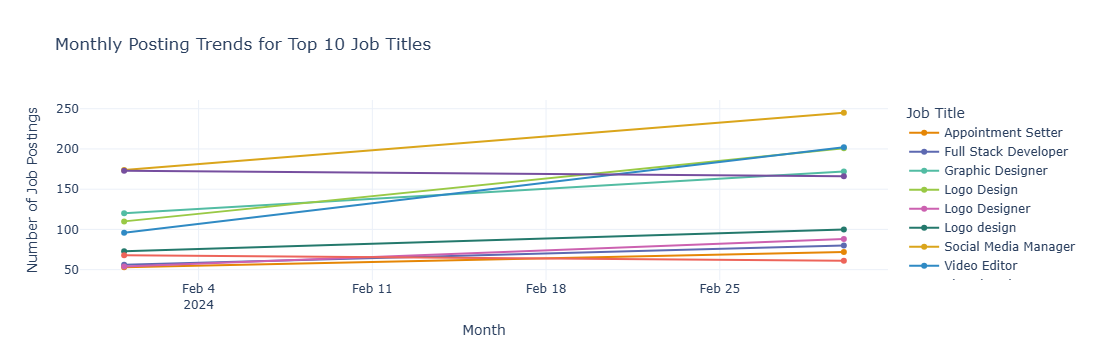

In [33]:
jobs = df.dropna(subset=['title', 'published_date']).copy()

# Remove timezone information before monthly grouping
jobs['Month'] = (jobs['published_date'].dt.tz_convert(None).dt.to_period('M').astype(str))

# Find the 10 most frequently posted job titles
top_titles = jobs['title'].value_counts().head(10).index

# Calculate monthly job postings for the selected titles
monthly_jobs = (jobs[jobs['title'].isin(top_titles)].groupby(['Month', 'title']).size().reset_index(name = 'Job Postings'))

display(monthly_jobs.sort_values(['title', 'Month']).head(20))

fig = px.line(monthly_jobs, x = 'Month', y = 'Job Postings', color = 'title', markers = True, title = 'Monthly Posting Trends for Top 10 Job Titles',
              color_discrete_sequence = px.colors.qualitative.Vivid)

fig.update_layout(template = 'plotly_white', xaxis_title = 'Month', yaxis_title = 'Number of Job Postings', legend_title = 'Job Title',
                  hovermode = 'x unified')

fig.show()

* Social Media Manager postings increased from **174** in February to **245** in March 2024.

* Video Editor postings increased from **96** to **202**.

* Logo Design postings increased from **110** to **201**.

* Virtual Assistant postings decreased from **173** to **166**.

* Website Development postings decreased from **68** to **61**.

# Emerging Job Categories - Growth Analysis

Month,title,2024-02,2024-03,Growth
0,Video Editor,96.0,202.0,106.0
1,Logo Design,110.0,201.0,91.0
2,Social Media Manager,174.0,245.0,71.0
3,Shopping mall store management,0.0,71.0,71.0
4,Graphic Designer,120.0,172.0,52.0
5,Lead Generation,38.0,83.0,45.0
6,Facebook ads manager,13.0,53.0,40.0
7,Logo Designer,54.0,88.0,34.0
8,Actualmente estamos contratando hispanohablantes y escritores para nuestro trabajo remoto.,10.0,43.0,33.0
9,I need to buy Google Play developer accounts.,0.0,32.0,32.0


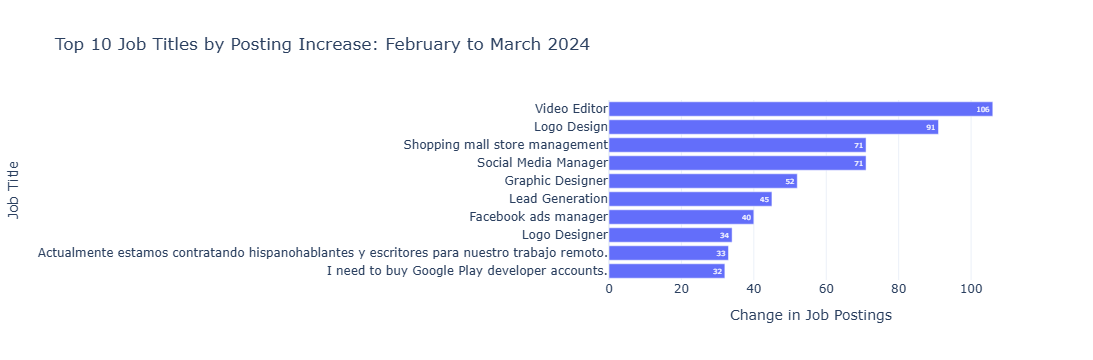

In [34]:
# Convert publication date into month
df['published_date'] = pd.to_datetime(df['published_date'], errors = 'coerce', utc = True)

df['Month'] = df['published_date'].dt.strftime('%Y-%m')

# Count job postings for each title in each month
monthly_jobs = df.groupby(['Month', 'title']).size().reset_index(name='Job_Postings')

# Compare February and March 2024
comparison = monthly_jobs[monthly_jobs['Month'].isin(['2024-02', '2024-03'])]

comparison = comparison.pivot(index = 'title', columns = 'Month', values = 'Job_Postings').fillna(0)

for month in ['2024-02', '2024-03']:
    if month not in comparison.columns:
        comparison[month] = 0

comparison['Growth'] = (comparison['2024-03'] - comparison['2024-02'])

comparison = comparison.sort_values('Growth', ascending = False)

# Show top 10 titles with the largest increase
top_jobs = comparison.head(10).reset_index()

display(top_jobs)

fig = px.bar(top_jobs, x = 'Growth', y = 'title', orientation = 'h', title = 'Top 10 Job Titles by Posting Increase: February to March 2024',
             labels = {'Growth': 'Change in Job Postings','title': 'Job Title'}, text = 'Growth')

fig.update_layout(template = 'plotly_white', yaxis = {'categoryorder': 'total ascending'})

fig.show()

* Job postings increased for some job titles from February to March 2024.

* This may indicate growing demand but uneven data coverage can affect the results.

# High-Demand Job Role Prediction

,Job Title,Predicted Next 7 Days,Average Daily Postings,MAE
0,Social Media Manager,66,2.91,5.45
1,Virtual Assistant,52,2.35,2.98
2,Logo Design,50,2.16,5.78
3,Video Editor,48,2.07,5.88
4,Graphic Designer,46,2.03,4.36


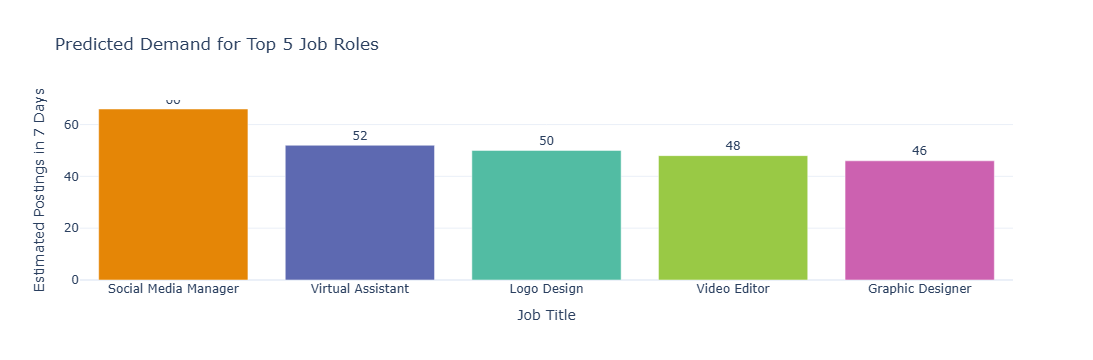

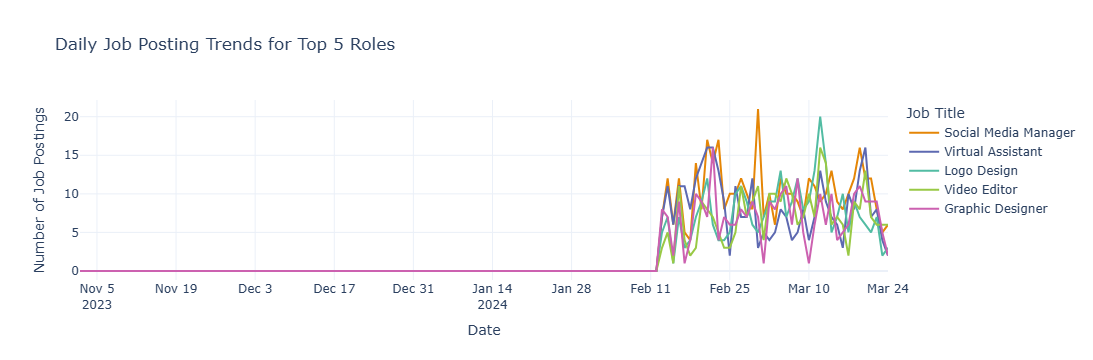

In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

jobs = df.dropna(subset=['title', 'published_date']).copy()
jobs['Date'] = jobs['published_date'].dt.tz_convert(None).dt.date

# Select top 5 job titles
top_titles = jobs['title'].value_counts().head(5).index

# Create daily dates
all_dates = pd.date_range(jobs['Date'].min(), jobs['Date'].max(), freq='D').date

results = []
trend_data = []

for title in top_titles:
    daily = (jobs[jobs['title'] == title].groupby('Date').size().reindex(all_dates, fill_value = 0))

    X = [[i] for i in range(len(daily))]
    y = daily.values

    # Evaluate the model using the latest 20% of days
    split = int(len(X) * 0.8)

    model = LinearRegression()
    model.fit(X[:split], y[:split])

    test_predictions = model.predict(X[split:])
    mae = mean_absolute_error(y[split:], test_predictions)

    # Predict demand for the next 7 days
    model.fit(X, y)
    future_X = [[i] for i in range(len(X), len(X) + 7)]
    future_predictions = model.predict(future_X)

    predicted_jobs = round(sum(max(0, p) for p in future_predictions))

    results.append({'Job Title': title, 'Predicted Next 7 Days': predicted_jobs, 'Average Daily Postings': round(y.mean(), 2), 'MAE': round(mae, 2)})

    # Store actual daily postings for the trend chart
    for date, count in zip(all_dates, y):
        trend_data.append({'Date': date, 'Job Title': title, 'Job Postings': count})

# Show prediction results
forecast_df = pd.DataFrame(results).sort_values('Predicted Next 7 Days', ascending=False)

display(forecast_df)

# Chart 1: Predicted demand
fig = px.bar(forecast_df, x = 'Job Title', y = 'Predicted Next 7 Days', color = 'Job Title', text = 'Predicted Next 7 Days',
             title = 'Predicted Demand for Top 5 Job Roles', color_discrete_sequence = px.colors.qualitative.Vivid)
fig.update_layout(template = 'plotly_white', xaxis_title = 'Job Title', yaxis_title = 'Estimated Postings in 7 Days', showlegend = False)
fig.update_traces(textposition='outside')
fig.show()

# Chart 2: Historical demand trends
trend_df = pd.DataFrame(trend_data)

fig = px.line(trend_df, x = 'Date', y = 'Job Postings', color = 'Job Title', title = 'Daily Job Posting Trends for Top 5 Roles',
              color_discrete_sequence = px.colors.qualitative.Vivid)
fig.update_layout(template = 'plotly_white', xaxis_title = 'Date', yaxis_title = 'Number of Job Postings', legend_title = 'Job Title', hovermode = 'x unified')

fig.show()

* Social Media Manager has the highest predicted demand, with **66** estimated postings over the next seven days.

* Virtual Assistant ranks second with **52** predicted postings.

* Graphic Designer has the lowest predicted demand among these five roles with **46** postings.

* The MAE values show that prediction errors are substantial for some roles especially Video Editor and Logo Design.

# Average Hourly Rates Across Countries

,country,Average_Hourly_Rate,Job_Count
6,Argentina,17.42,149
51,Egypt,17.55,239
96,Latvia,17.94,111
35,China,18.01,424
183,Unknown,18.24,2014
177,Ukraine,18.46,577
44,Cyprus,18.82,167
81,Indonesia,19.39,234
180,United States,19.78,48195
91,Kenya,22.08,369


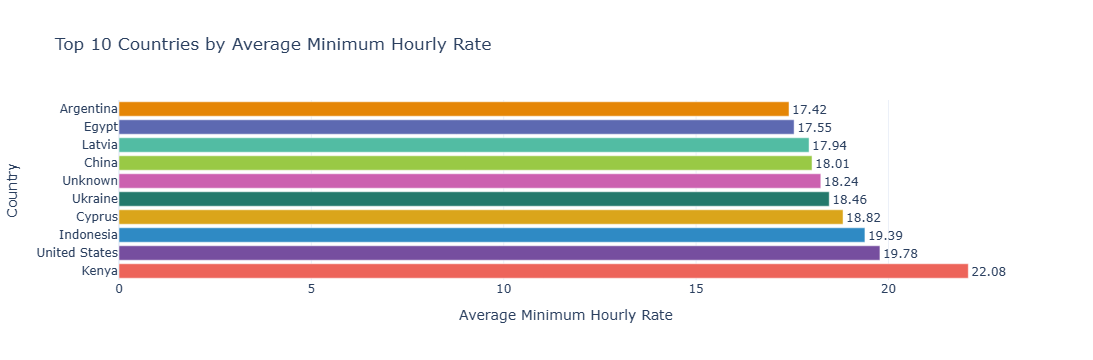

In [36]:
hourly_jobs = df[(df['is_hourly'] == True) & (df['country'].notna()) & (df['hourly_low'].notna()) & (df['hourly_low'] >= 0)].copy()

# Calculate average hourly rate and job count by country
country_rates = (hourly_jobs.groupby('country').agg(Average_Hourly_Rate = ('hourly_low', 'mean'), Job_Count = ('hourly_low', 'count')).reset_index())

# Keep countries with at least 100 hourly job records
country_rates = country_rates[country_rates['Job_Count'] >= 100]

# Select the 10 countries with highest average hourly rates
country_rates = country_rates.nlargest(10, 'Average_Hourly_Rate').sort_values('Average_Hourly_Rate', ascending = True)

display(country_rates.round({'Average_Hourly_Rate': 2}))

fig = px.bar(country_rates, x = 'Average_Hourly_Rate', y = 'country', orientation = 'h', color = 'country', text = 'Average_Hourly_Rate',
             hover_data = ['Job_Count'], title = 'Top 10 Countries by Average Minimum Hourly Rate', color_discrete_sequence = px.colors.qualitative.Vivid)

fig.update_traces(texttemplate = '%{text:.2f}', textposition = 'outside')

fig.update_layout(template = 'plotly_white', xaxis_title = 'Average Minimum Hourly Rate', yaxis_title = 'Country', showlegend = False)

fig.show()

* Kenya has the highest average hourly rate among the countries shown at **22.08**.

* The United States has an average hourly rate of **19.78** and the largest number of jobs in this comparison with **48,195** records.

* Indonesia has an average hourly rate of **19.39** across **234** job records.

# Job Recommendation Engine

Popular job titles:


,title,Job Count
0,Social Media Manager,419
1,Virtual Assistant,339
2,Logo Design,311
3,Video Editor,298
4,Graphic Designer,292
5,Logo design,173
6,Logo Designer,142
7,Full Stack Developer,136
8,Website Development,129
9,Appointment Setter,125


,title,country,is_hourly,hourly_low,hourly_high,budget,published_date,link
244788,Graphic designer needed for logo for webshop,Netherlands,False,NaN,NaN,15.0,2024-03-24 13:31:52+00:00,https://www.upwork.com/jobs/Graphic-designer-needed-for-logo-for-webshop_%7E010c5102980cfba691?s...
244719,Graphic Designer needed asap to edit this image,Australia,True,NaN,NaN,NaN,2024-03-24 13:21:33+00:00,https://www.upwork.com/jobs/Graphic-Designer-needed-asap-edit-this-image_%7E0132ad1034140c2356?s...
244736,Graphic Designer for pitch deck,United Kingdom,False,NaN,NaN,20.0,2024-03-24 13:14:02+00:00,https://www.upwork.com/jobs/Graphic-Designer-for-pitch-deck_%7E018a4d2b508939f80f?source=rss
241161,2D graphic designer,United Arab Emirates,False,NaN,NaN,150.0,2024-03-24 13:01:51+00:00,https://www.upwork.com/jobs/graphic-designer_%7E0140083051bffb3cae?source=rss
240930,Seeking Exceptional Graphic Designer for Travel Companion Brand Identity Overhaul!,Spain,False,NaN,NaN,200.0,2024-03-24 12:41:57+00:00,https://www.upwork.com/jobs/Seeking-Exceptional-Graphic-Designer-for-Travel-Companion-Brand-Iden...
240929,Video Editor and Graphic Designer,Canada,False,NaN,NaN,50.0,2024-03-24 12:41:18+00:00,https://www.upwork.com/jobs/Video-Editor-and-Graphic-Designer_%7E0129719471f1b448da?source=rss
239386,Graphic designer,Israel,False,NaN,NaN,25.0,2024-03-24 12:11:29+00:00,https://www.upwork.com/jobs/Graphic-designer_%7E019aa8bb2b0fbf96a3?source=rss
235246,Meme Website Designer &amp; Graphic Designer,Malaysia,True,15.0,30.0,NaN,2024-03-24 11:34:14+00:00,https://www.upwork.com/jobs/Meme-Website-Designer-amp-Graphic-Designer_%7E012db53748e5162939?sou...
235004,Graphic Designer for Sales Brochure Creation,France,True,15.0,35.0,NaN,2024-03-24 11:29:28+00:00,https://www.upwork.com/jobs/Graphic-Designer-for-Sales-Brochure-Creation_%7E016e53065b90335209?s...
231297,Graphic Designer for Garment and Cup Designs,Pakistan,True,15.0,35.0,NaN,2024-03-24 10:50:46+00:00,https://www.upwork.com/jobs/Graphic-Designer-for-Garment-and-Cup-Designs_%7E010d65cbce8e657da0?s...


Matching jobs found: 3835


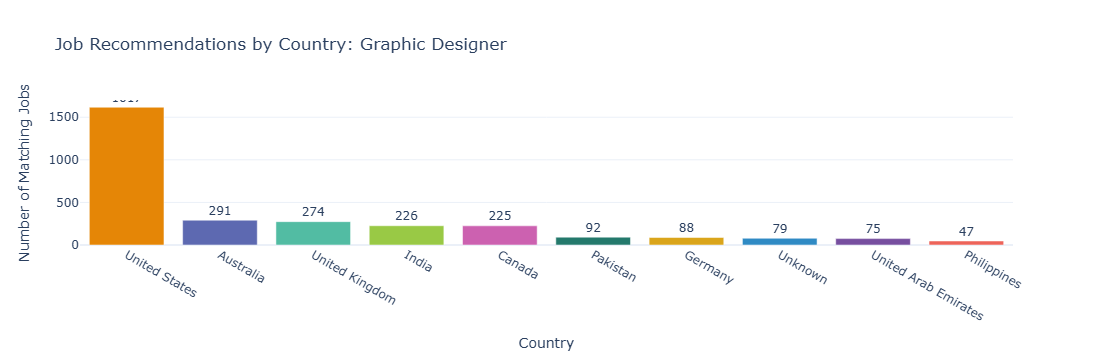

In [37]:
from IPython.display import display

# Prepare job data
jobs = df.dropna(subset=['title']).copy()
jobs['title'] = jobs['title'].astype(str)

# Show popular job titles for reference
print("Popular job titles:")
display(jobs['title'].value_counts().head(10).reset_index(name='Job Count').rename(columns={'index': 'Job Title'}))

preferred_title = "Graphic Designer"

# Find matching job titles
recommended = jobs[jobs['title'].str.contains(preferred_title, case=False, na=False, regex=False)].copy()

if not recommended.empty:
    # Keep useful details
    columns_to_show = [
        col for col in ['title', 'country', 'is_hourly', 'hourly_low', 'hourly_high', 'budget',
            'published_date', 'link'] 
        if col in recommended.columns]

    # Show up to 10 recommendations
    display(recommended[columns_to_show].sort_values('published_date', ascending = False).head(10))

    print(f"Matching jobs found: {len(recommended)}")

    country_counts = (recommended['country'].fillna('Unknown').value_counts().head(10).reset_index())
    country_counts.columns = ['Country', 'Job Count']

    fig = px.bar(country_counts, x = 'Country', y = 'Job Count', color = 'Country', text = 'Job Count', title = f'Job Recommendations by Country: {preferred_title}',
                 color_discrete_sequence=px.colors.qualitative.Vivid)

    fig.update_layout(template = 'plotly_white', xaxis_title = 'Country', yaxis_title = 'Number of Matching Jobs', showlegend = False)
    fig.update_traces(textposition='outside')
    fig.show()

else:
    print("No matching jobs found. Try a broader title, ""such as Designer, Developer, or Manager.")


* The recommendation engine found **3,835** job postings matching the preferred title **Graphic Designer**.

* The system displays up to **10** matching jobs including job title, country, payment type, available rate or budget, publication date and job link.

# Monthly Job Market Dashboard

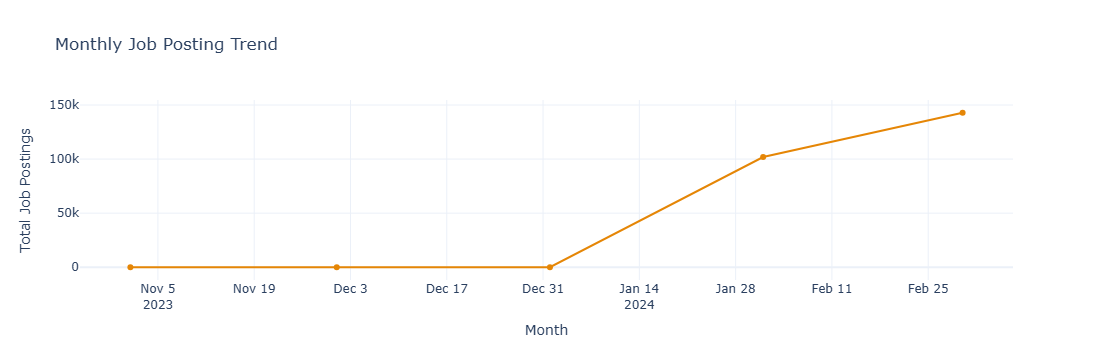

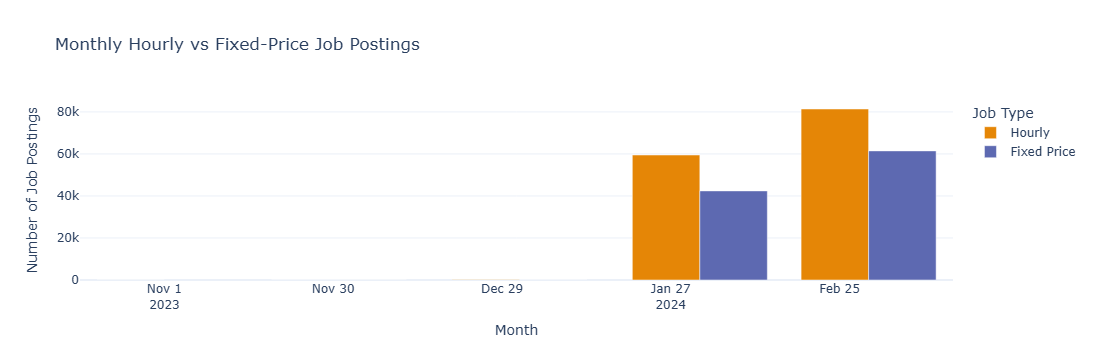

,Month,Job Postings
0,2023-11,1
1,2023-12,10
2,2024-01,96
3,2024-02,101886
4,2024-03,142834


In [38]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Prepare monthly data
dashboard_data = df.dropna(subset=['published_date']).copy()

dashboard_data['Month'] = (dashboard_data['published_date'].dt.tz_convert(None).dt.to_period('M').astype(str))

# Monthly total job postings
monthly_total = (dashboard_data.groupby('Month').size().reset_index(name='Job Postings'))

# Monthly postings by job type
monthly_type = (dashboard_data.groupby(['Month', 'is_hourly']).size().reset_index(name='Job Postings'))

monthly_type['Job Type'] = monthly_type['is_hourly'].map({True: 'Hourly',False: 'Fixed Price'})

# Chart 1: Total monthly job postings
fig1 = px.line(monthly_total, x = 'Month', y = 'Job Postings', markers = True, title = 'Monthly Job Posting Trend',
               color_discrete_sequence = px.colors.qualitative.Vivid)

fig1.update_layout(template = 'plotly_white', xaxis_title = 'Month', yaxis_title = 'Total Job Postings')
fig1.show()

# Chart 2: Monthly job type comparison
fig2 = px.bar(monthly_type, x = 'Month', y = 'Job Postings', color = 'Job Type', barmode = 'group', title = 'Monthly Hourly vs Fixed-Price Job Postings',
              color_discrete_sequence = px.colors.qualitative.Vivid)

fig2.update_layout(template = 'plotly_white', xaxis_title = 'Month', yaxis_title = 'Number of Job Postings', legend_title = 'Job Type')
fig2.show()

display(monthly_total)

* March 2024 has the highest number of recorded job postings with **1,42,834** records.

* February 2024 contains **1,01,886** records.

* The dataset has very few records for November 2023, December 2023, and January 2024 compared with February and March.

# Remote Work Trends

Total job postings: 244827
Titles mentioning remote work: 1351
Percentage of titles mentioning remote keywords: 0.55 %


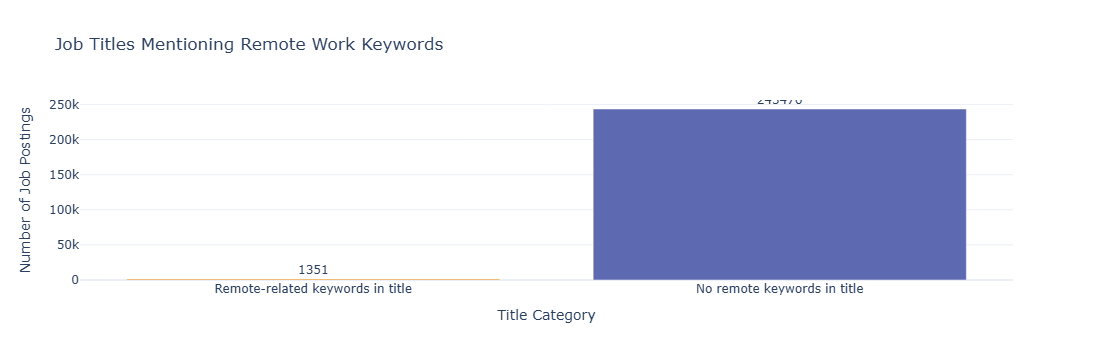

Examples of job titles mentioning remote keywords:


,title,country,published_date
116,Remote Dental Educator (Treatment Coordinator),Australia,2024-02-19 08:24:50+00:00
216,Remote Booking Agent/Customer Service,United States,2024-02-14 04:00:59+00:00
423,"Sematic segmentation using remote sensing and python , CNN",Unknown,2024-02-17 14:49:26+00:00
441,"+/- 30 min Mobile Usability Test for Mentorist App, $15, Fully Remote",Estonia,2024-02-17 14:45:45+00:00
503,Work from home cold calling,United Kingdom,2024-02-16 16:12:53+00:00
512,Remote,United States,2024-02-16 16:12:16+00:00
605,Remote CNC operator and trainer,Tanzania,2024-02-16 20:13:36+00:00
676,Networking Administration Administrative Support Remote Positions,United States,2024-02-15 19:05:49+00:00
770,Remote Job Opportunity,United States,2024-02-17 09:40:37+00:00
1931,Seeking for Senior Web Developer(Remote),United States,2024-02-19 08:41:35+00:00


In [39]:
remote_keywords = r'\b(?:remote|work from home|work-from-home|wfh)\b'

remote_jobs = df[df['title'].str.contains(remote_keywords, case = False, na = False, regex = True)].copy()

# Calculate counts
total_jobs = len(df)
matched_jobs = len(remote_jobs)
other_jobs = total_jobs - matched_jobs

percentage = (round(matched_jobs / total_jobs * 100, 2)
    if total_jobs > 0 else 0)

print("Total job postings:", total_jobs)
print("Titles mentioning remote work:", matched_jobs)
print("Percentage of titles mentioning remote keywords:", percentage, "%")

chart_data = pd.DataFrame({'Category': ['Remote-related keywords in title', 'No remote keywords in title'], 'Job Postings': [matched_jobs, other_jobs]})

fig = px.bar(chart_data, x = 'Category', y = 'Job Postings', color = 'Category', text = 'Job Postings', title = 'Job Titles Mentioning Remote Work Keywords',
             color_discrete_sequence = px.colors.qualitative.Vivid)

fig.update_layout(template = 'plotly_white', xaxis_title = 'Title Category', yaxis_title = 'Number of Job Postings', showlegend = False)

fig.update_traces(textposition='outside')
fig.show()

print("Examples of job titles mentioning remote keywords:")

display(remote_jobs[['title', 'country', 'published_date']].head(10))

* The dataset contains **2,44,827** job postings.

* A total of **1,351** job titles were identified by the remote-work keyword search.

* These postings represent approximately **0.55%** of all records.

# Remote Work Trends Summary

Total Jobs: 244827
Remote-Related Jobs: 1380
Remote-Related Percentage: 0.56 %


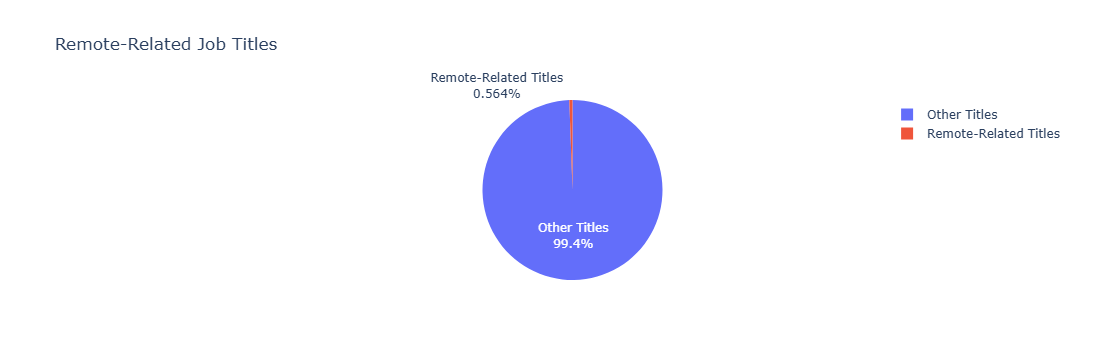

In [40]:
remote_jobs = df[df['title'].str.contains('remote|work from home|work-from-home|wfh', case = False, na = False)]

# Count total and remote-related jobs
total_jobs = len(df)
remote_count = len(remote_jobs)

remote_percentage = (remote_count / total_jobs) * 100

print("Total Jobs:", total_jobs)
print("Remote-Related Jobs:", remote_count)
print("Remote-Related Percentage:", round(remote_percentage, 2), "%")

chart_data = pd.DataFrame({'Job Type': ['Remote-Related Titles', 'Other Titles'],'Job Count': [remote_count,total_jobs - remote_count]})

fig = px.pie(chart_data, names = 'Job Type', values = 'Job Count', title = 'Remote-Related Job Titles')

fig.update_traces(textinfo='label+percent')
fig.show()

# Future Job Market Trends

Last month in dataset: 2024-03
Forecast month: 2024-04
Estimated job postings: 165228


,Month,Job Postings,Type
0,2023-11,1,Actual
1,2023-12,10,Actual
2,2024-01,96,Actual
3,2024-02,101886,Actual
4,2024-03,142834,Actual
5,2024-04,165228,Forecast


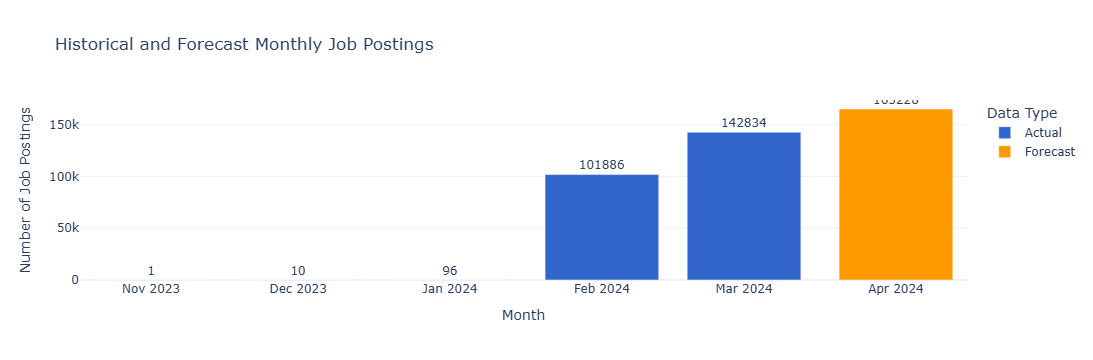

In [41]:
from sklearn.linear_model import LinearRegression

jobs = df.dropna(subset=['published_date']).copy()

jobs['Month'] = (jobs['published_date'].dt.tz_convert(None).dt.to_period('M').astype(str))

monthly_jobs = (jobs.groupby('Month').size().reset_index(name = 'Job Postings').sort_values('Month').reset_index(drop = True))

# Create month index
monthly_jobs['Month_Index'] = range(len(monthly_jobs))

# Train a simple model
X = monthly_jobs[['Month_Index']]
y = monthly_jobs['Job Postings']

model = LinearRegression()
model.fit(X, y)

# Predict the next month
next_index = len(monthly_jobs)
next_prediction = max(0, model.predict(pd.DataFrame({'Month_Index': [next_index]}))[0])

# Create next month label
last_month = pd.Period(monthly_jobs['Month'].iloc[-1], freq='M')
next_month = str(last_month + 1)

print("Last month in dataset:", last_month)
print("Forecast month:", next_month)
print("Estimated job postings:", round(next_prediction))

# Show historical data and forecast together
forecast_row = pd.DataFrame({'Month': [next_month],'Job Postings': [round(next_prediction)],'Type': ['Forecast']})

monthly_jobs['Type'] = 'Actual'
chart_data = pd.concat([monthly_jobs[['Month', 'Job Postings', 'Type']], forecast_row], ignore_index = True)

display(chart_data)

# Plot historical postings and forecast
fig = px.bar(chart_data, x = 'Month', y = 'Job Postings', color = 'Type', text = 'Job Postings', title = 'Historical and Forecast Monthly Job Postings',
             color_discrete_map = {'Actual': '#3366CC', 'Forecast': '#FF9900'})

fig.update_layout(template = 'plotly_white', xaxis_title = 'Month', yaxis_title = 'Number of Job Postings', legend_title = 'Data Type')

fig.update_traces(textposition='outside')
fig.show()

* The model estimates approximately **1,65,228** job postings for April 2024.

* This value is a forecast generated from historical monthly posting counts not an actual April observation.

# Future Job Market Forecast

,Scenario,Job Postings
0,Low Estimate,148705
1,Expected Estimate,165228
2,High Estimate,181751


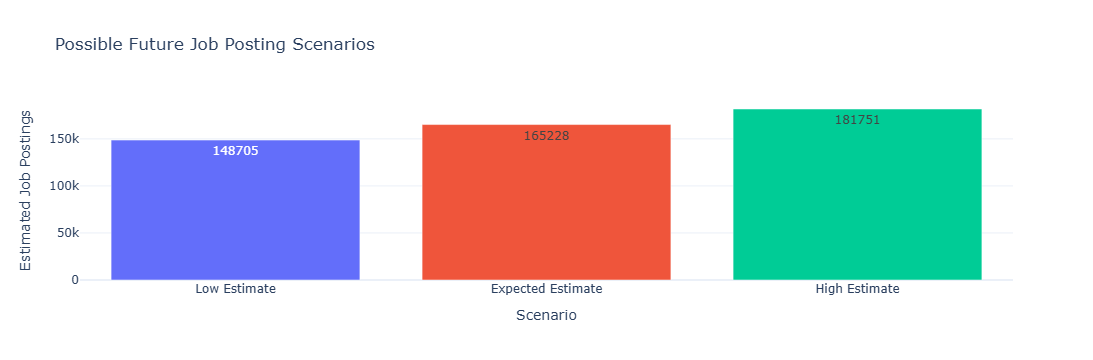

In [42]:
forecast_value = round(float(next_prediction))

# Create three possible scenarios
scenario_data = pd.DataFrame({'Scenario': ['Low Estimate', 'Expected Estimate', 'High Estimate'],
                              'Job Postings': [round(forecast_value * 0.90), forecast_value, round(forecast_value * 1.10)]})

display(scenario_data)

fig = px.bar(scenario_data, x = 'Scenario', y = 'Job Postings', color = 'Scenario', text = 'Job Postings',
             title = 'Possible Future Job Posting Scenarios')

fig.update_layout(template = 'plotly_white', xaxis_title = 'Scenario', yaxis_title = 'Estimated Job Postings', showlegend = False)

fig.show()

* The expected estimate is **1,65,228** postings while the low and high estimates are approximately **10%** below and above the expected value.